# Diagnóstico de marca empleadora — Tesla vs. peers
## Sentimiento (transformers) + topic modeling (BERTopic) sobre reseñas de Glassdoor

**Encargo de RRHH:** identificar los puntos fuertes y las áreas de mejora de Tesla como empleador a partir de lo que dicen sus empleados en Glassdoor, y compararlos con sus competidores directos.

**Peers elegidos:** Ford, General Motors, Stellantis y Honda. Son fabricantes de automóviles generalistas con plantas de producción, red comercial e ingeniería propias, y compiten por el mismo talento que Tesla (operarios de planta, ingenieros, técnicos y personal de ventas y entrega). Todos superan las 1.000 reseñas.

| Sección | Contenido |
|---|---|
| 0 | Carga y preparación |
| 1 | EDA: rating, recomendación, actuales vs. antiguos, evolución temporal |
| 2 | Sentimiento en pros y cons (control de calidad) |
| 3 | Topic modeling con BERTopic y categorías de negocio |
| 4 | Comparación con peers: % por categoría, balance neto, contraste con el rating y evolución |
| 5 | Empleados actuales vs. antiguos: motivos de salida |
| 6 | Matriz de priorización |
| 7 | Conclusiones y recomendaciones para RRHH |


---
## 0. Carga y preparación

In [1]:
import os
import re
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

TARGET = 'Tesla'
PEERS = ['Ford-Motor-Company', 'General-Motors-GM', 'Stellantis', 'Honda']
FIRMS = [TARGET] + PEERS

# Páginas de Glassdoor que necesitan tratamiento
FCA = 'FCA-Fiat-Chrysler-Automobiles'   # histórico de Stellantis antes de la fusión de 2021
GM_DUP = 'General-Motors-(GM)'          # página duplicada de General Motors: NO se usa

# Tope de reseñas por empresa
MAX_POR_EMPRESA = 2000
SEED = 42

# Colores fijos en todos los gráficos: Tesla en rojo, peers en tonos neutros
COLORES = {'Tesla': '#E31937', 'Ford-Motor-Company': '#1F4E79', 'General-Motors-GM': '#5B9BD5',
           'Stellantis': '#7F7F7F', 'Honda': '#A9A9A9', 'Peers': '#404040', 'Media peers': '#404040'}

### 0.1 Duplicados entre páginas de Glassdoor

Glassdoor tiene a veces varias páginas para la misma empresa. Antes de cargar los datos compruebo los dos casos que afectan a este análisis:

- **General Motors** aparece como "General-Motors-GM" y como "General-Motors-(GM)". La celda siguiente comprueba que son las mismas reseñas, así que uso solo "General-Motors-GM". 
- **Stellantis** nace en enero de 2021 de la fusión FCA + PSA, y su página solo tiene reseñas desde 2021. Integro la página de "FCA-Fiat-Chrysler-Automobiles" como su histórico, porque es la misma organización antes y después de la fusión y no comparte reseñas con la página de Stellantis. Así el peer cubre toda la ventana temporal.

In [2]:
# Considero que dos reseñas son la misma si coinciden en fecha, pros y cons
claves = ['date_review', 'pros', 'cons']

# General Motors: ¿cuántas reseñas de la página duplicada están también en la principal?
gm = pd.read_parquet('glassdoor_reviews_hr.parquet',
                     filters=[('firm', 'in', ['General-Motors-GM', GM_DUP])])
solape_gm = gm[gm['firm'] == 'General-Motors-GM'].merge(gm[gm['firm'] == GM_DUP][claves], on=claves)
print(f"Reseñas de {GM_DUP}: {(gm['firm'] == GM_DUP).sum():,} | "
      f"idénticas en General-Motors-GM: {len(solape_gm):,}")
# Resultado: 5,021 de 5,025 -> es la misma empresa duplicada, se descarta General-Motors-(GM)

# Stellantis y FCA: compruebo que NO comparten reseñas antes de unirlas
st = pd.read_parquet('glassdoor_reviews_hr.parquet', filters=[('firm', 'in', ['Stellantis', FCA])])
solape_st = st[st['firm'] == 'Stellantis'].merge(st[st['firm'] == FCA][claves], on=claves)
print(f"Reseñas comunes entre Stellantis y FCA: {len(solape_st)}")
print('Fechas de cada página:')
print(st.groupby('firm')['date_review'].agg(['min', 'max']))
del gm, st, solape_gm, solape_st

Reseñas de General-Motors-(GM): 5,025 | idénticas en General-Motors-GM: 5,021
Reseñas comunes entre Stellantis y FCA: 0
Fechas de cada página:
                                      min         max
firm                                                 
FCA-Fiat-Chrysler-Automobiles  2018-07-29  2023-03-10
Stellantis                     2021-01-06  2023-06-13


### 0.2 Carga y vista general de los datos

In [3]:
# Cargo solo las empresas del análisis: el filtro se aplica al leer, sin cargar el parquet entero
raw = pd.read_parquet('glassdoor_reviews_hr.parquet', filters=[('firm', 'in', FIRMS + [FCA])])

# FCA pasa a contar como Stellantis (histórico pre-fusión)
raw['firm'] = raw['firm'].replace({FCA: 'Stellantis'})

# Seguridad: elimino posibles reseñas repetidas dentro de una misma empresa tras la unión
raw = raw.drop_duplicates(subset=['firm'] + claves)

print(f'Reseñas cargadas: {len(raw):,}')
raw.head()

Reseñas cargadas: 20,268


,firm,date_review,current,overall_rating,recommend,pros,cons
0,Stellantis,2018-07-29,"Former Employee, more than 1 year",2.0,x,Unexpected good opportunities can happen,No career planning. Low salaries compared to similar positions in other companies.
1,Stellantis,2018-07-29,Current Employee,5.0,v,Precious insights in the automotive industry. Great name and firm. Competitive pay,Low workload at the beginning.
2,Stellantis,2018-07-30,Current Employee,4.0,v,Competitive salary. Good benefits even though they push a HSA. Plenty of opportunities for career advancement.,Employee discount for purchasing vehicles is not the best.
3,Stellantis,2018-07-31,Former Employee,4.0,v,Enjoyed the working environment and the products.,Sometimes delayed HR communications at times.
4,Stellantis,2018-07-31,Current Employee,1.0,o,None that I can think of,Too many to list on here


In [4]:
# Descripción de las columnas: tipo, nulos y valores distintos
columnas = pd.DataFrame({
    'tipo': raw.dtypes.astype(str),
    'nulos': raw.isna().sum(),
    'valores distintos': raw.nunique(),
})
columnas

,tipo,nulos,valores distintos
firm,str,0,5
date_review,object,0,1779
current,str,0,14
overall_rating,float64,0,5
recommend,str,0,3
pros,str,0,19884
cons,str,0,20046


La columna nulos está a 0 en todas las variables: no hay valores vacíos y no hace falta imputar nada.

### 0.3 Situación del empleado

La columna "current" mezcla situación y antigüedad (Former Employee, more than 3 years). Para simplificar me quedo solo con la situación: empleado actual o antiguo.

In [5]:
# 'Current Employee...' -> Actual, 'Former Employee...' -> Antiguo
def situacion(s):
    s = str(s).lower()
    if s.startswith('current'):
        return 'Actual'
    if s.startswith('former'):
        return 'Antiguo'
    return 'Desconocido'

raw['situacion'] = raw['current'].map(situacion)
print(raw['situacion'].value_counts())

raw = raw[raw['situacion'].isin(['Actual', 'Antiguo'])]

situacion
Actual     12777
Antiguo     7491
Name: count, dtype: int64


### 0.4 Muestra de trabajo

In [6]:
# Muestra aleatoria con semilla fija: hasta 2.000 reseñas por empresa.
# Honda (1.313) entra completa; en el resto el muestreo aleatorio mantiene la distribución por año y situación.
df = pd.concat([g.sample(n=min(MAX_POR_EMPRESA, len(g)), random_state=SEED)
                for _, g in raw.groupby('firm')], ignore_index=True)
df['review_id'] = np.arange(len(df))   # identificador estable de cada reseña

# Variables derivadas
df['recomienda'] = df['recommend'].map({'v': 'Sí', 'o': 'Neutral', 'x': 'No'})
df['date_review'] = pd.to_datetime(df['date_review'])
df['anio'] = df['date_review'].dt.year
df['grupo'] = np.where(df['firm'] == TARGET, TARGET, 'Peers')   # Tesla frente al conjunto de peers

# Limpieza de saltos de línea y espacios repetidos.
for col in ['pros', 'cons']:
    df[col] = df[col].astype(str).str.replace(r'\s+', ' ', regex=True).str.strip()


In [7]:
# Cantidad de de reseñas de muestra por empresa y situación del empleado
print(f'Muestra de trabajo: {len(df):,} reseñas\n')
pd.crosstab(df['firm'], df['situacion'], margins=True, margins_name='Total')

Muestra de trabajo: 9,313 reseñas



situacion,Actual,Antiguo,Total
firm,,,
Ford-Motor-Company,1324,676,2000
General-Motors-GM,1340,660,2000
Honda,756,557,1313
Stellantis,1362,638,2000
Tesla,1111,889,2000
Total,5893,3420,9313


In [8]:
# Primera y última reseña de cada empresa
fechas = df.groupby('firm')['date_review'].agg(primera='min', ultima='max').reindex(FIRMS)
fechas.loc['Total'] = [df['date_review'].min(), df['date_review'].max()]
display(fechas)


,primera,ultima
firm,,
Tesla,2018-07-31,2023-05-02
Ford-Motor-Company,2018-08-01,2023-03-15
General-Motors-GM,2018-08-04,2023-06-15
Stellantis,2018-07-30,2023-06-13
Honda,2018-08-02,2023-03-20
Total,2018-07-30,2023-06-15


In [9]:
# Reseñas por año y empresa
pd.crosstab(df['anio'], df['firm'], margins=True, margins_name='Total')[FIRMS + ['Total']]

firm,Tesla,Ford-Motor-Company,General-Motors-GM,Stellantis,Honda,Total
anio,,,,,,
2018,117,103,97,79,49,445
2019,263,243,336,198,125,1165
2020,251,277,278,269,192,1267
2021,576,614,528,659,463,2840
2022,589,659,506,609,413,2776
2023,204,104,255,186,71,820
Total,2000,2000,2000,2000,1313,9313


In [10]:
# Reparto de la recomendación en la muestra
df['recomienda'].value_counts(normalize=True).mul(100).round(1).to_frame('% reseñas')

,% reseñas
recomienda,
Sí,45.4
Neutral,34.2
No,20.4


**Notas sobre la muestra**:
- 9.313 reseñas: 2.000 por empresa y 1.313 de Honda.
- La ventana va del 30/07/2018 al 15/06/2023. 2018 empieza en julio y 2023 termina a mitad de año, por eso esos dos años tienen bastantes menos reseñas en la tabla por año.
- Un 34 % de las reseñas no opina sobre la recomendación (`o` → Neutral), así que el "% que recomienda" es bajo en todas las empresas. Lo interpreto junto con el % que no recomienda.

---
## 1. EDA

En todas las tablas, la fila Media peers es la media simple de las cuatro empresas (no ponderada por número de reseñas), para que todas pesen lo mismo como referencia de mercado.

In [11]:
# Funciones auxiliares que se usan en el resto del notebook
def media_peers(tabla):
    # Ordena la tabla por empresa y añade una fila con la media simple de los 4 peers
    t = tabla.reindex(FIRMS).copy()
    t.loc['Media peers'] = t.loc[PEERS].mean()
    return t

def pct(cond):
    # Porcentaje de valores True de una condición
    return cond.mean() * 100

def nombre_corto(firma):
    return firma.split('-')[0] if firma in FIRMS else firma

### 1.1 Resumen por empresa

Cada fila es una empresa y cada columna un indicador:

| Columna | Qué es |
|---|---|
| Reseñas disponibles | Total de reseñas de la empresa en el dataset |
| Reseñas muestra | Reseñas usadas en el análisis |
| Rating medio | Media de `overall_rating` (escala 1–5) |
| % recomienda / % no recomienda | Porcentaje de reseñas con `recommend` = v / x |
| % antiguos | Porcentaje de reseñas escritas por antiguos empleados (el resto son actuales) |
| % 1-2 estrellas | Porcentaje de reseñas que puntúan con 1 o 2 estrellas (muy insatisfechas) |

In [12]:
resumen = df.groupby('firm').agg(**{
    'Reseñas muestra': ('review_id', 'size'),
    'Rating medio': ('overall_rating', 'mean'),
    '% recomienda': ('recomienda', lambda s: pct(s == 'Sí')),
    '% no recomienda': ('recomienda', lambda s: pct(s == 'No')),
    '% antiguos': ('situacion', lambda s: pct(s == 'Antiguo')),
    '% 1-2 estrellas': ('overall_rating', lambda s: pct(s <= 2)),
})
resumen.insert(0, 'Reseñas disponibles', raw['firm'].value_counts())
resumen = media_peers(resumen)
# Formato: recuentos sin decimales (la media de peers no aplica a los recuentos), indicadores con 2 decimales
resumen.loc['Media peers', ['Reseñas disponibles', 'Reseñas muestra']] = np.nan
resumen.style.format('{:.2f}').format('{:,.0f}', subset=['Reseñas disponibles', 'Reseñas muestra'], na_rep='—')

,Reseñas disponibles,Reseñas muestra,Rating medio,% recomienda,% no recomienda,% antiguos,% 1-2 estrellas
firm,,,,,,,
Tesla,"5,437","2,000",3.59,43.50,26.30,44.45,19.70
Ford-Motor-Company,"5,370","2,000",3.98,49.05,14.35,33.80,8.40
General-Motors-GM,"5,289","2,000",3.82,52.15,19.05,33.00,13.90
Stellantis,"2,859","2,000",3.48,37.65,24.50,31.90,18.65
Honda,"1,313","1,313",3.84,44.10,16.30,42.42,11.35
Media peers,—,—,3.78,45.74,18.55,35.28,13.07


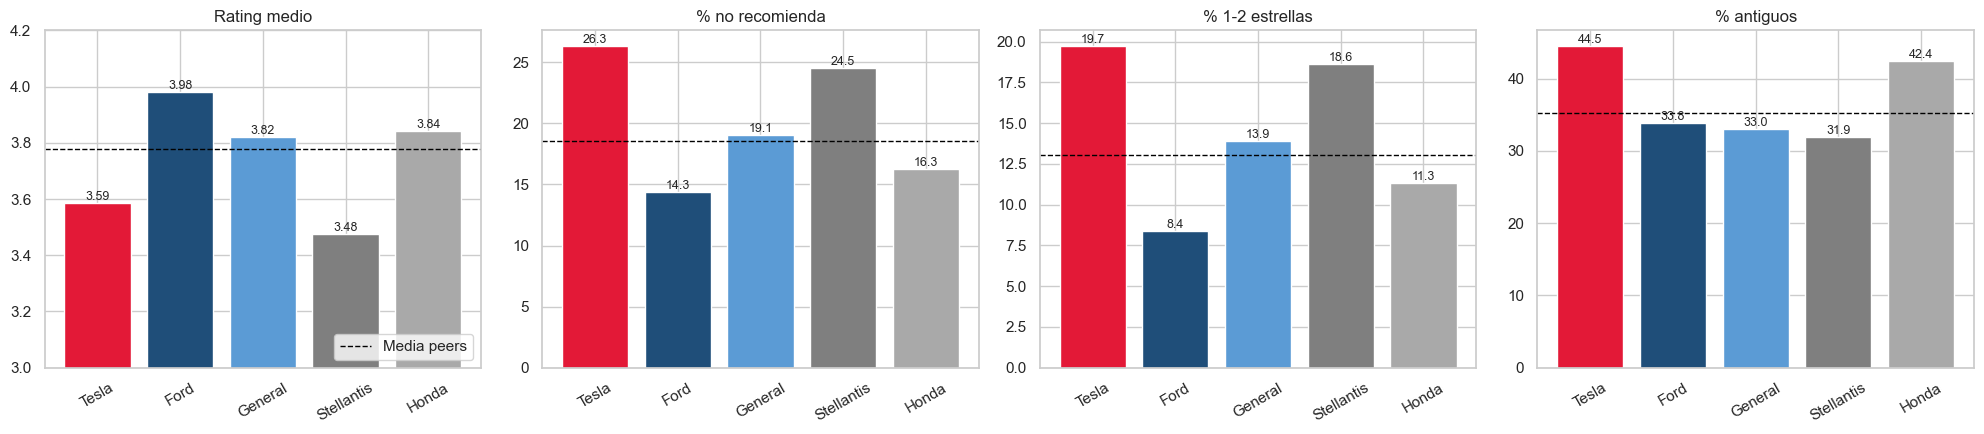

In [13]:
# Los 4 indicadores clave en gráficos de barras; la línea discontinua es la media de los peers
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
metricas = ['Rating medio', '% no recomienda', '% 1-2 estrellas', '% antiguos']
for ax, col in zip(axes, metricas):
    valores = resumen.loc[FIRMS, col]
    ax.bar(range(len(FIRMS)), valores, color=[COLORES[f] for f in FIRMS])
    ax.axhline(resumen.loc['Media peers', col], color='black', ls='--', lw=1, label='Media peers')
    ax.set_xticks(range(len(FIRMS)))
    ax.set_xticklabels([nombre_corto(f) for f in FIRMS], rotation=30)
    ax.set_title(col)
    for i, v in enumerate(valores):   # valor encima de cada barra
        ax.text(i, v, f'{v:.2f}' if col == 'Rating medio' else f'{v:.1f}', ha='center', va='bottom', fontsize=9)
axes[0].set_ylim(3, 4.2)
axes[0].legend(loc='lower right')
plt.tight_layout(); plt.show()

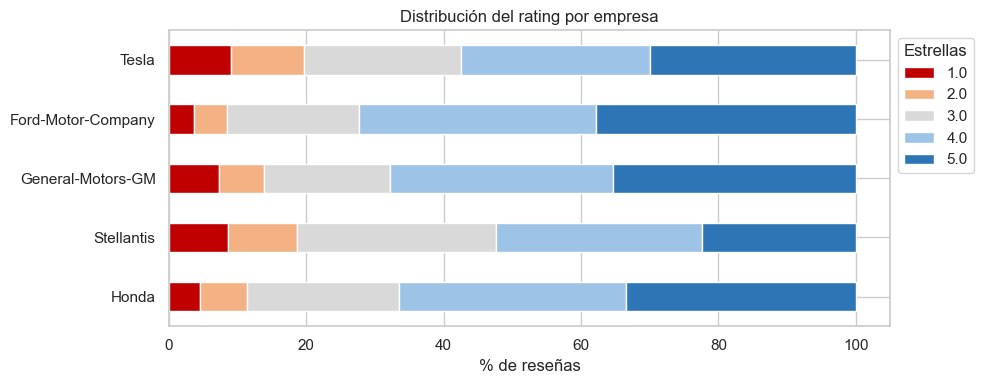

overall_rating,1.0,2.0,3.0,4.0,5.0
firm,,,,,
Tesla,9.0,10.7,22.8,27.6,29.9
Ford-Motor-Company,3.6,4.8,19.2,34.5,37.8
General-Motors-GM,7.4,6.6,18.2,32.4,35.4
Stellantis,8.6,10.0,28.9,30.0,22.4
Honda,4.6,6.8,22.1,33.1,33.4


In [14]:
# Distribución completa del rating para comprobar si las medias se ven afectadas por pocas reseñas muy malas o muchas reseñas neutras
dist = pd.crosstab(df['firm'], df['overall_rating'], normalize='index').reindex(FIRMS) * 100
ax = dist.plot(kind='barh', stacked=True, figsize=(10, 4),
               color=['#C00000', '#F4B183', '#D9D9D9', '#9DC3E6', '#2E75B6'])
ax.set_xlabel('% de reseñas'); ax.set_ylabel('')
ax.legend(title='Estrellas', bbox_to_anchor=(1, 1)); ax.invert_yaxis()
plt.title('Distribución del rating por empresa'); plt.tight_layout(); plt.show()
dist.round(1)

### 1.2 Empleados actuales vs. antiguos

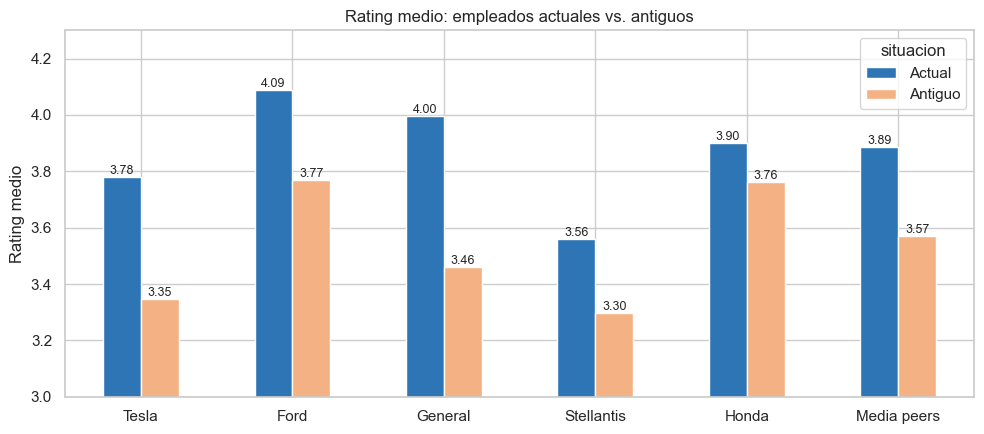

In [15]:
# Rating medio de actuales y antiguos por empresa
act_ant = media_peers(df.pivot_table(index='firm', columns='situacion', values='overall_rating', aggfunc='mean'))

ax = act_ant[['Actual', 'Antiguo']].plot(kind='bar', figsize=(10, 4.5), color=['#2E75B6', '#F4B183'])
ax.set_ylim(3, 4.3); ax.set_ylabel('Rating medio'); ax.set_xlabel('')
ax.set_xticklabels([nombre_corto(f) for f in act_ant.index], rotation=0)
for cont in ax.containers:            # valor encima de cada barra
    ax.bar_label(cont, fmt='%.2f', fontsize=9)
plt.title('Rating medio: empleados actuales vs. antiguos'); plt.tight_layout(); plt.show()

### 1.3 Evolución del rating (julio 2018 – junio 2023)

2018 y 2023 son años parciales (ver la tabla de reseñas por año de la sección 0).

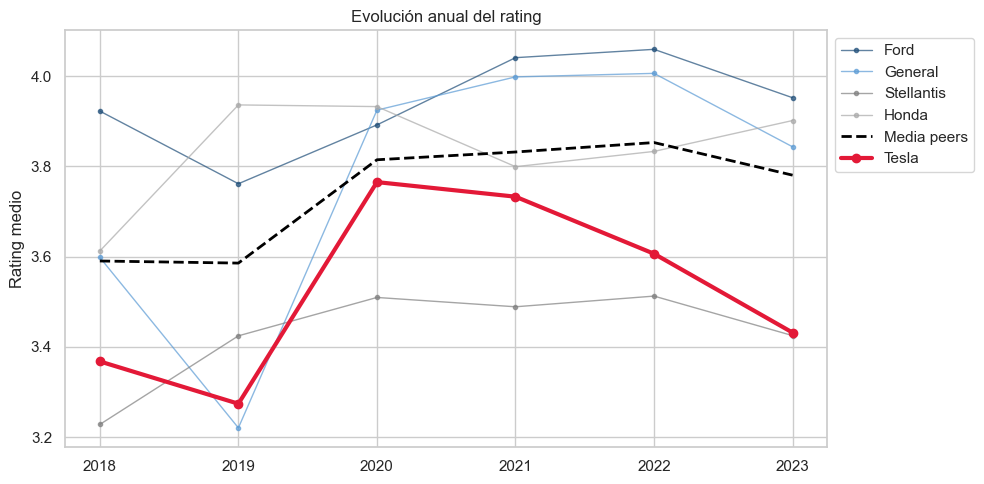

firm,Tesla,Ford-Motor-Company,General-Motors-GM,Stellantis,Honda,Media peers
anio,,,,,,
2018,3.37,3.92,3.60,3.23,3.61,3.59
2019,3.27,3.76,3.22,3.42,3.94,3.59
2020,3.76,3.89,3.92,3.51,3.93,3.81
2021,3.73,4.04,4.00,3.49,3.80,3.83
2022,3.61,4.06,4.01,3.51,3.83,3.85
2023,3.43,3.95,3.84,3.42,3.90,3.78


In [16]:
# Rating medio por año y empresa
evol = df.pivot_table(index='anio', columns='firm', values='overall_rating', aggfunc='mean')[FIRMS]
evol['Media peers'] = evol[PEERS].mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 5))
for f in PEERS:
    ax.plot(evol.index, evol[f], color=COLORES[f], lw=1, alpha=0.7, marker='o', ms=3, label=nombre_corto(f))
ax.plot(evol.index, evol['Media peers'], color='black', lw=2, ls='--', label='Media peers')
ax.plot(evol.index, evol[TARGET], color=COLORES[TARGET], lw=3, marker='o', label='Tesla')
ax.set_ylabel('Rating medio'); ax.set_title('Evolución anual del rating')
ax.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

evol.round(2)

In [17]:
# Antes y después de 2020: la pandemia cambia condiciones de trabajo, producción y teletrabajo
df['periodo'] = np.where(df['anio'] < 2020, '2018-2019', '2020-2023')
periodo = media_peers(df.pivot_table(index='firm', columns='periodo', values='overall_rating', aggfunc='mean'))
periodo['cambio'] = periodo['2020-2023'] - periodo['2018-2019']
periodo.round(2)

periodo,2018-2019,2020-2023,cambio
firm,,,
Tesla,3.30,3.65,0.35
Ford-Motor-Company,3.81,4.02,0.21
General-Motors-GM,3.30,3.96,0.66
Stellantis,3.37,3.49,0.13
Honda,3.84,3.84,-0.00
Media peers,3.58,3.83,0.25


### 1.4 Longitud de los textos

Los modelos tipo BERT procesan un máximo de 512 tokens. Compruebo cuántos textos podrían superarlo para saber si el truncado afecta al análisis.

In [18]:
# Una palabra equivale aproximadamente a 1,3 tokens: 350 palabras ~ 512 tokens
for col in ['pros', 'cons']:
    n_pal = df[col].str.split().str.len()
    print(f"{col}: mediana {n_pal.median():.0f} palabras | percentil 95 {n_pal.quantile(0.95):.0f} | "
          f"textos > 350 palabras: {(n_pal > 350).sum()}")

pros: mediana 7 palabras | percentil 95 27 | textos > 350 palabras: 2
cons: mediana 8 palabras | percentil 95 50 | textos > 350 palabras: 15


Son textos cortos (mediana de 6–8 palabras). El truncado solo afectará a unas pocas reseñas.

### Conclusiones

1. **Tesla está por debajo del mercaddo.** Tiene un rating medio de 3,59 frente a 3,78 de la media de peers, también es la empresa con mayor porcentaje de no recomendación y con mayor valoraciones de 1/2 estrellas.
2. **La valoración está polarizada.** Tesla tiene un 29,9 % de reseñas de 5 estrellas, en línea con los peers (22–38 %), pero la mayor proporción de 1 y 2 estrellas. Hay un grupo de empleados muy satisfecho y otro muy insatisfecho.
3. **Tesla tiene la mayor proporción de antiguos empleados** (44,4 % frente a 35,3 % de media en los peers). Además, sus antiguos empleados son de los que peor puntúan de las cinco empresas. Quienes se van de Tesla se van más descontentos que en la competencia.
4. **La tendencia empeora desde 2021.** Tesla mejora de 2019 a 2020 (de 3,27 a 3,76) y luego cae cada año (3,73 en 2021, 3,61 en 2022 y 3,43 en 2023), mientras los peers se mantienen estables en torno a 3,8–3,9. La diferencia entre las empresas se abre cada vez mas en comparación con Tesla.


---
## 2. Sentimiento en pros y cons (control de calidad)

En Glassdoor el empleado ya separa lo positivo (pros) de lo negativo (cons), así que el sentimiento esperado se conoce de antemano.

Modelo: "distilbert-base-uncased-finetuned-sst-2-english".
- Es un transformer preentrenado en inglés, el idioma de las reseñas.
- Es binario (POSITIVE / NEGATIVE, sin clase neutral),.
- Uso `truncation=True` para los textos largos vistos anteriormente.
- Para tardar menos en reejecuciones he implementado que se guarde en disco los datos de una muestra, si cambia esa muestra se ejecutaría desde 0 otra vez.

In [19]:
MODELO_SENT = 'distilbert-base-uncased-finetuned-sst-2-english'

def huella(textos):
    # Resumen (hash) del contenido de los textos: si cambia la muestra, cambia la huella.
    # Se usa en el nombre del fichero de caché para no reutilizar resultados de otra muestra.
    return hashlib.md5('||'.join(textos).encode('utf-8')).hexdigest()[:10]

def sentimiento(textos, nombre):
    textos = list(textos)
    ruta = f'cache_sent_{nombre}_{huella(textos)}.parquet'

    # 1) Si ya existe la caché de ESTA muestra, se carga y no se vuelve a ejecutar el modelo
    if os.path.exists(ruta):
        print(f'{nombre}: cargado de caché ({ruta})')
        return pd.read_parquet(ruta)

    # 2) Si no, se ejecuta el modelo por lotes de 64 textos
    import torch
    from transformers import pipeline
    clf = pipeline('sentiment-analysis', model=MODELO_SENT,
                   device=0 if torch.cuda.is_available() else -1)
    res = clf(textos, batch_size=64, truncation=True, max_length=512)

    # 3) Se guarda el resultado (etiqueta y confianza de cada texto) para la próxima ejecución
    out = pd.DataFrame({'label': [r['label'] for r in res], 'score': [r['score'] for r in res]})
    out.to_parquet(ruta)
    return out

# Se aplica por separado a pros y cons. El resultado tiene el mismo orden que df.
for col in ['pros', 'cons']:
    s = sentimiento(df[col], col)
    df[f'sent_{col}'] = s['label'].values
    # 'score' es la confianza en la etiqueta predicha; la paso a probabilidad de POSITIVO (0-1)
    df[f'p_pos_{col}'] = np.where(s['label'] == 'POSITIVE', s['score'], 1 - s['score'])

pros: cargado de caché (cache_sent_pros_acf14398ec.parquet)
cons: cargado de caché (cache_sent_cons_40a4e0fce3.parquet)


In [20]:
# % de pros positivos y % de cons negativos por empresa
control = df.groupby('firm').agg(**{
    '% pros positivos': ('sent_pros', lambda s: pct(s == 'POSITIVE')),
    '% cons negativos': ('sent_cons', lambda s: pct(s == 'NEGATIVE')),
})
control = media_peers(control)
control.loc['Total muestra'] = [pct(df['sent_pros'] == 'POSITIVE'), pct(df['sent_cons'] == 'NEGATIVE')]
control.round(1)

,% pros positivos,% cons negativos
firm,,
Tesla,89.4,82.2
Ford-Motor-Company,94.2,79.2
General-Motors-GM,93.8,82.5
Stellantis,89.7,82.8
Honda,91.2,79.1
Media peers,92.2,80.9
Total muestra,91.7,81.3


### 2.1 Casos discordantes

Un tipo de discordancia encontrado son los cons sin queja real ("none that I can think of", "nothing bad to say"). El modelo los clasifica como positivos porque lo son, no indican un problema. Los detecto con una regla de texto y los separo, luego lo seguiré usando.

In [21]:
# Regla para detectar cons sin queja: el texto empieza por una fórmula de "nada que decir"
# (none, nothing, no cons, can't think...), es corto y no añade una queja
# después con un conector ("nothing bad, just the hours" sí es una queja).
PATRON_SIN_QUEJA = re.compile(r'''^\W*(
    none\b | nil\b | n/?a\s*\W*$ |
    nothing(\s*[.!,]|\s*$|\s+(bad|negative|to\s+(say|complain|mention|report)|i\s+can|that\s+i|really|
            at\s+all|so\s+far|as\s+such|specific|stands?\s+out|comes?\s+to\s+mind|much\s+to\s+say|
            nothing|in\s+particular|major|significant|yet|for\s+now)) |
    no\s+(real\s+|major\s+|significant\s+)?(cons?|complaints?|negatives?|downsides?)\b |
    (i\s+)?(can'?t|cannot|could\s?n'?t)\s+think
)''', re.I | re.X)
CONECTOR_QUEJA = re.compile(r'\b(but|just|except|expect|other\s+th[ae]n|besides|apart\s+from)\b', re.I)

def es_sin_queja(texto):
    return (bool(PATRON_SIN_QUEJA.match(texto)) and len(texto.split()) <= 15
            and not CONECTOR_QUEJA.search(texto))

df['cons_sin_queja'] = df['cons'].map(es_sin_queja)
print(f"Cons sin queja real: {df['cons_sin_queja'].sum()} ({pct(df['cons_sin_queja']):.1f} % de las reseñas)")

cons_pos = df[df['sent_cons'] == 'POSITIVE']
print(f"Cons clasificados como positivos: {len(cons_pos)}, de los cuales "
      f"{pct(cons_pos['cons_sin_queja']):.0f} % son 'sin queja'")

# Control de calidad recalculado sin los 'sin queja' (que son positivos legítimamente)
print(f"% cons negativos excluyendo los 'sin queja': "
      f"{pct(df.loc[~df['cons_sin_queja'], 'sent_cons'] == 'NEGATIVE'):.1f} %")

Cons sin queja real: 486 (5.2 % de las reseñas)
Cons clasificados como positivos: 1740, de los cuales 11 % son 'sin queja'
% cons negativos excluyendo los 'sin queja': 82.6 %


In [22]:
# Muestra para lectura manual: pros negativos, cons positivos que no son sin queja,
# y cons sin queja para verificar que la regla funciona
cols = ['firm', 'overall_rating', 'pros', 'cons']
print('=== PROS clasificados como NEGATIVOS ===')
display(df[df['sent_pros'] == 'NEGATIVE'].sample(5, random_state=SEED)[cols])
print('=== CONS clasificados como POSITIVOS (sin contar los "sin queja") ===')
display(df[(df['sent_cons'] == 'POSITIVE') & ~df['cons_sin_queja']].sample(5, random_state=SEED)[cols])
print('=== CONS marcados como "sin queja" ===')
display(df[df['cons_sin_queja']].sample(5, random_state=SEED)[['firm', 'cons']])

=== PROS clasificados como NEGATIVOS ===


,firm,overall_rating,pros,cons
6998,Stellantis,1.0,I honestly have nothing positive to say about this company.,Toxic work environment. Nepotism culture. Senior management runs this place like thugs. There is no work-lufe balanc...
3551,General-Motors-GM,4.0,"There is a lot of room for growth, good benefits, raises, profit sharing,’",hours and lack of respect from superiors
5404,Stellantis,1.0,Chrysler discount on vehicle purchases and money toward college classes.,There is little training for new hires regarding company specific software and general job duties.
5873,Stellantis,1.0,"401k match, PTO, holiday vacations","Overworked, no appreciation or recognition, no clear expectations, poor culture and leadership, will be doing multip..."
7443,Tesla,2.0,was awarded some stock grants,ceo is weird and crazy


=== CONS clasificados como POSITIVOS (sin contar los "sin queja") ===


,firm,overall_rating,pros,cons
953,Ford-Motor-Company,2.0,Great job on the first,Greatest Hits Music of the
6677,Stellantis,5.0,"Training, opportunities, good life, interesting work, good company culture",Time to progress inside the company Benefits
161,Ford-Motor-Company,4.0,"Digital / data analytics transformation, automation etc","Improvement on new technologies, employees education for new technology"
1039,Ford-Motor-Company,5.0,great company great projects friendly people,Nothing much . everything is great .
5772,Stellantis,5.0,"Multinational exposure, global assignments and lots of opportunity to grow your career","Industrial Culture still very strong, like ""command and control"""


=== CONS marcados como "sin queja" ===


,firm,cons
7719,Tesla,none it a great place to work
4029,Honda,No cons no cons no cons no cons
8053,Tesla,None that I can find
8624,Tesla,nothing nothing nothing nothing nothing
6349,Stellantis,No cons to my knowledge.


### 2.2 Coherencia entre el sentimiento y el rating

Si el modelo funciona, las reseñas con cons más negativos deberían tener peor rating. Agrupo las reseñas en cuatro tramos según la probabilidad de que su con sea positivo, ordenados de más negativo a más positivo. La comprobación es correcta si el rating medio sube de un tramo al siguiente.

In [23]:
# Tramos según la probabilidad de positivo del con (0 = seguro negativo, 1 = seguro positivo)
df['tramo_cons'] = pd.cut(df['p_pos_cons'], [0, 0.05, 0.5, 0.95, 1], include_lowest=True,
                          labels=['muy negativo', 'negativo', 'positivo', 'muy positivo'])
coherencia = (df.groupby('tramo_cons', observed=True)['overall_rating']
                .agg(rating_medio='mean', n_reseñas='size').round(2))
display(coherencia)

,rating_medio,n_reseñas
tramo_cons,,
muy negativo,3.59,7028
negativo,4.02,545
positivo,4.05,390
muy positivo,4.27,1350


**Lectura de los casos discordantes.**

Con este modelo si que considero que he separado correctamente la gran mayoría (aún se ven excepciones) de cons sin queja, pero los pros calificados como negativos siguen siendo un problema a seguir trabajando en ellos. Igualmente se puede sacar información de estos casos discordantes.

- Cons "sin queja" ("None that I can find"). No son un error: el empleado no tiene quejas.
- Cons redactados en positivo o como consejo ("Time to progress inside the company Benefits"). Describen un aspecto bueno que a lo mejor quería añadir como pro o en otros casos son recomendacione sa seguir haciendo.

---
## 3. Topic modeling con BERTopic

Usando BERTopic el objetivo es descubrir de qué hablan los empleados en sus pros y en sus cons, sin definir los temas de antemano.
Usaré un único modelo para las 5 empresas juntas (uno para pros y otro para cons). Así un tema significa lo mismo en Tesla y en Ford, y los porcentajes se pueden comparar.

In [24]:
from bertopic import BERTopic
from umap import UMAP
from hdbscan import HDBSCAN
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

MODELO_EMB = 'all-MiniLM-L6-v2'
MIN_CLUSTER = 90         # tamaño mínimo de un tema (~1 % de las reseñas)

# Stopwords: las de inglés + nombres de empresas + palabras genéricas que no aportan
STOP = list(ENGLISH_STOP_WORDS | {
    'tesla', 'ford', 'gm', 'general', 'motors', 'stellantis', 'fca', 'fiat', 'chrysler', 'honda',
    'company', 'job', 'pros', 'cons', 'lot', 'lots', 'really', 'just', 'pretty', 'like',
    'don', 'doesn', 'didn', 'isn', 've', 'll', 'im', 'thing', 'things',
    'dont', 'doesnt', 'didnt', 'isnt', 'cant', 'wont', 'good', 'great'})

def embeddings(textos, nombre):
    # Convierte cada texto en un vector de 384 números que resume su significado.
    # Igual que con el sentimiento, se guarda en caché con la huella de la muestra.
    textos = list(textos)
    ruta = f'cache_emb_{nombre}_{huella(textos)}.npy'
    if os.path.exists(ruta):
        print(f'{nombre}: embeddings cargados de caché ({ruta})')
        return np.load(ruta)
    from sentence_transformers import SentenceTransformer
    modelo = SentenceTransformer(MODELO_EMB)
    emb = modelo.encode(textos, batch_size=128, show_progress_bar=True)
    np.save(ruta, emb)
    return emb

def entrenar_bertopic(docs, emb):
    # 1) UMAP reduce los vectores de 384 a 5 dimensiones conservando qué textos son parecidos
    umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED)
    # 2) HDBSCAN agrupa los textos cercanos en temas; los que no encajan quedan como outliers (-1)
    hdbscan_model = HDBSCAN(min_cluster_size=MIN_CLUSTER, min_samples=10, metric='euclidean',
                            cluster_selection_method='eom', prediction_data=True)
    # 3) CountVectorizer + c-TF-IDF extraen las palabras más características de cada tema
    vectorizer = CountVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5)
    modelo = BERTopic(umap_model=umap_model, hdbscan_model=hdbscan_model,
                      vectorizer_model=vectorizer, top_n_words=10, calculate_probabilities=False)
    # Paso los embeddings ya calculados para no volver a calcularlos dentro de BERTopic
    topics, _ = modelo.fit_transform(docs, embeddings=emb)
    return modelo, np.array(topics), vectorizer

### 3.1 Entrenamiento: un modelo para pros y otro para cons

In [25]:
# Fijo las semillas de numpy, random y torch para que el resultado sea lo más reproducible posible
import random
np.random.seed(SEED); random.seed(SEED)
try:
    import torch; torch.manual_seed(SEED)
except ImportError:
    pass

# PROS: todas las reseñas
docs_pros = df['pros'].tolist()
emb_pros = embeddings(docs_pros, 'pros')
modelo_pros, topics_pros, vec_pros = entrenar_bertopic(docs_pros, emb_pros)

# CONS: sin los "sin queja", que tendrán su propia categoría
mask_cons = ~df['cons_sin_queja'].values
docs_cons = df.loc[mask_cons, 'cons'].tolist()
emb_cons = embeddings(docs_cons, 'cons')
modelo_cons, topics_cons, vec_cons = entrenar_bertopic(docs_cons, emb_cons)

for nombre, t in [('pros', topics_pros), ('cons', topics_cons)]:
    print(f"{nombre}: {len(set(t)) - (1 if -1 in t else 0)} topics | outliers: {pct(t == -1):.1f} %")

pros: embeddings cargados de caché (cache_emb_pros_acf14398ec.npy)
cons: embeddings cargados de caché (cache_emb_cons_8b5d7d95ed.npy)
pros: 25 topics | outliers: 24.0 %
cons: 20 topics | outliers: 35.6 %


### 3.2 Tratamiento de los outliers

HDBSCAN deja sin tema (topic −1) las reseñas que no encajan con claridad en ningún grupo. He decidido reasignar las que se parezcan lo suficiente y el resto decjarlo como "otros"

Para ello cada outlier se asigna al tema más parecido (similitud entre su embedding y el del tema) solo si la similitud supera 0,4 (Mediante pruebas he decidido seleccionar este número, a mayor es el número quedarán mas outliers y se reasignarán menos reseñas y viceversa si el número es menor). El resto queda en "Otros", que se muestra en las tablas pero no se interpreta.

In [26]:
def reasignar_outliers(modelo, docs, topics, emb, vectorizer):
    nuevos = modelo.reduce_outliers(docs, topics, strategy='embeddings',
                                    embeddings=emb, threshold=0.4)
    # Recalculo las palabras clave de cada tema con las reseñas reasignadas
    modelo.update_topics(docs, topics=nuevos, vectorizer_model=vectorizer)
    return np.array(nuevos)

antes_p, antes_c = pct(topics_pros == -1), pct(topics_cons == -1)
topics_pros = reasignar_outliers(modelo_pros, docs_pros, topics_pros, emb_pros, vec_pros)
topics_cons = reasignar_outliers(modelo_cons, docs_cons, topics_cons, emb_cons, vec_cons)
print(f'Outliers en pros: {antes_p:.1f} % -> {pct(topics_pros == -1):.1f} %')
print(f'Outliers en cons: {antes_c:.1f} % -> {pct(topics_cons == -1):.1f} %')

2026-10-07 17:07:21,711 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.
2026-10-07 17:07:21,845 - BERTopic - WARNING: Using a custom list of topic assignments may lead to errors if topic reduction techniques are used afterwards. Make sure that manually assigning topics is the last step in the pipeline.Note that topic embeddings will also be created through weightedc-TF-IDF embeddings instead of centroid embeddings.


Outliers en pros: 24.0 % -> 2.4 %
Outliers en cons: 35.6 % -> 6.5 %


### 3.3 De topics a categorías de negocio

Una vez BERTopics ha creado los grupos de reseñas parecidas y se han trabajo sus outliers ahora hay que definir las categorías.
Para ello he creado 12 categorías distintas y en cada una de ellas palabras clave para relacionarlas, en caso de que las reseñas no coincidan con ninguna iran a "otros".

Alta dirección la separo de Dirección y management porque en Tesla sucede un caso concreto donde la gente nombra directamente a Elon Musk, con lo que es muy diferente a quejas o puntos positivos de un jefe de un sector de la empresa.

In [27]:
# Palabras de referencia de cada categoría
CATEGORIAS = {
    'Compensación y beneficios':     ['pay', 'salary', 'compensation', 'benefits', 'bonus', 'stock', 'wages', 'insurance', 'discount'],
    'Conciliación y horarios':       ['balance', 'hours', 'schedule', 'overtime', 'shift', 'weekends', 'flexible', 'remote', 'vacation'],
    'Ritmo y carga de trabajo':      ['fast', 'pace', 'pressure', 'stress', 'workload', 'burnout', 'demanding', 'understaffed'],
    'Dirección y management':        ['management', 'manager', 'managers', 'supervisor', 'supervisors', 'boss', 'micromanagement', 'favoritism', 'hr'],
    'Alta dirección y estrategia':   ['ceo', 'elon', 'musk', 'executives', 'upper', 'leadership', 'vision', 'strategy'],
    'Carrera y desarrollo':          ['career', 'growth', 'promotion', 'advancement', 'opportunities', 'learning', 'training', 'development'],
    'Cultura y compañeros':          ['people', 'culture', 'team', 'coworkers', 'colleagues', 'environment', 'friendly', 'toxic'],
    'Misión, producto e innovación': ['mission', 'product', 'cars', 'vehicles', 'innovation', 'technology', 'electric', 'future'],
    'Estabilidad y contratos':       ['layoffs', 'stability', 'security', 'union', 'contract', 'temp', 'fired', 'turnover'],
    'Organización y procesos':       ['bureaucracy', 'politics', 'process', 'processes', 'slow', 'disorganized', 'communication', 'chaos'],
    'Condiciones e instalaciones':   ['safety', 'plant', 'factory', 'line', 'conditions', 'equipment', 'parking', 'location'],
}
CATS_NEGOCIO = list(CATEGORIAS)                         # categorías
CATS_TODAS = CATS_NEGOCIO + ['Sin quejas', 'Otros']     # + las otras dos categorías

In [28]:
def categoria_auto(palabras_peso):
    # palabras_peso: lista de (palabra, peso c-TF-IDF) de un topic.
    # Cada categoría suma el peso de las palabras del topic que están en su lista de referencia
    # (en un bigrama basta con que coincida una de sus dos palabras). Gana la que más suma.
    puntos = {cat: sum(peso for pal, peso in palabras_peso
                       if any(p in ref for p in pal.split()))
              for cat, ref in CATEGORIAS.items()}
    mejor = max(puntos, key=puntos.get)
    return mejor if puntos[mejor] > 0 else 'Otros'

def tabla_topics(modelo, topics):
    # Una fila por topic: palabras, tamaño, % sobre el total de reseñas, un ejemplo de reseña y la categoría asignada
    filas = []
    for t in sorted(set(topics) - {-1}):
        t = int(t)  # BERTopic exige int de Python
        palabras = modelo.get_topic(t)
        filas.append({'topic': t,
                      'palabras': ' / '.join(p for p, _ in palabras[:3]),
                      'n reseñas': int((topics == t).sum()),
                      'ejemplo': modelo.get_representative_docs(t)[0][:150],
                      'categoria': categoria_auto(palabras)})
    tabla = (pd.DataFrame(filas)
               .sort_values('n reseñas', ascending=False)
               .set_index('topic'))
    # % sobre todas las reseñas (incluidas las que quedan en "Otros"), por eso no suma 100
    tabla.insert(2, '% del total', (tabla['n reseñas'] / len(topics) * 100).round(1))
    return tabla

tabla_pros = tabla_topics(modelo_pros, topics_pros)
tabla_cons = tabla_topics(modelo_cons, topics_cons)

**Topics de pros generados por BERTopic** y categoría asignada automáticamente (ordenados por tamaño):

In [29]:
tabla_pros.head(5)

,palabras,n reseñas,% del total,ejemplo,categoria
topic,,,,,
0,pay / pay benefits / benefits,1317,14.1,good pay and great benefits,Compensación y beneficios
1,environment / people / friendly,863,9.3,Harmonious work environment and great people to work with,Cultura y compañeros
2,culture / work culture / culture work,564,6.1,The culture of the company.,Cultura y compañeros
3,balance / life / life balance,559,6.0,Good work and life balance,Conciliación y horarios
4,car / cars / automotive,497,5.3,bike car marketing to be done,"Misión, producto e innovación"


**Topics de cons:**

In [30]:
tabla_cons.head(5)

,palabras,n reseñas,% del total,ejemplo,categoria
topic,,,,,
0,pay / salary / low,1041,11.8,The pay is in yang credits,Compensación y beneficios
1,management / leadership / managers,939,10.6,Management and that is all,Dirección y management
4,hours / long / long hours,778,8.8,Long hours that ware you down,Conciliación y horarios
3,work / workload / stressful,761,8.6,"High stress work environment, underpayment for work, childishness of employees",Ritmo y carga de trabajo
2,layoffs / people / cars,602,6.8,"Everything else. Company is a total mess, thanks to everything revolving around petty office politics. Departments d...",Estabilidad y contratos


In [31]:
# Categoría de cada topic (el índice de la tabla es el número de topic)
cat_topic_pros = tabla_pros['categoria'].to_dict()
cat_topic_cons = tabla_cons['categoria'].to_dict()

# Categoría de cada reseña: outliers que quedan -> 'Otros'; cons "sin queja" -> 'Sin quejas'
df['cat_pros'] = pd.Series(topics_pros).map(cat_topic_pros).fillna('Otros').values

df['topic_cons'] = -1
df.loc[mask_cons, 'topic_cons'] = topics_cons
df['cat_cons'] = df['topic_cons'].map(cat_topic_cons).fillna('Otros')
df.loc[df['cons_sin_queja'], 'cat_cons'] = 'Sin quejas'

# % de reseñas (5 empresas juntas) en cada categoría
resumen_cat = pd.DataFrame({
    '% reseñas pros': df['cat_pros'].value_counts(normalize=True) * 100,
    '% reseñas cons': df['cat_cons'].value_counts(normalize=True) * 100,
}).reindex(CATS_TODAS).fillna(0)
resumen_cat.round(1)

,% reseñas pros,% reseñas cons
Compensación y beneficios,26.0,11.2
Conciliación y horarios,12.6,14.9
Ritmo y carga de trabajo,1.6,8.2
Dirección y management,2.6,14.2
Alta dirección y estrategia,1.6,1.3
Carrera y desarrollo,7.6,7.1
Cultura y compañeros,23.0,5.2
"Misión, producto e innovación",10.8,0.0
Estabilidad y contratos,0.0,8.1
Organización y procesos,0.0,9.7


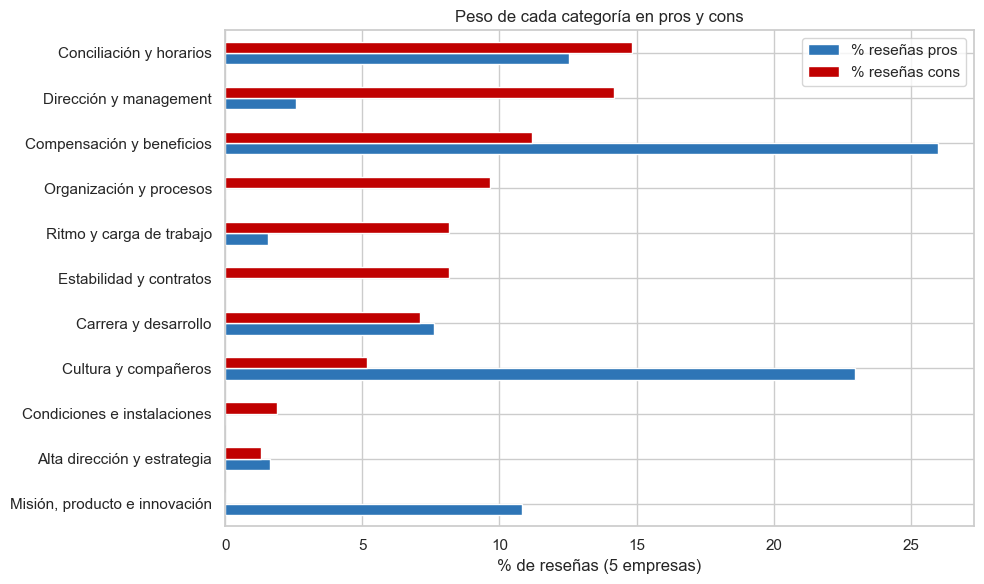

In [32]:
ax = resumen_cat.loc[CATS_NEGOCIO].sort_values('% reseñas cons').plot(
    kind='barh', figsize=(10, 6), color=['#2E75B6', '#C00000'])
ax.set_xlabel('% de reseñas (5 empresas)'); ax.set_ylabel('')
plt.title('Peso de cada categoría en pros y cons'); plt.tight_layout(); plt.show()

**Conclusión:** 
Se puede observar que como dato geenral que este sector lo mejor que ofrece son sus salarios y el entorno con los compañeros. Por el otro lado los puntos negativos no hay una gran diferencia pero si destacan los malos horarios y problemas con los superiores.

Esto es de gran ayuda porque ya podemos saber en que campos debemos seguir manteniendo las mismas metodogías y formas de trabajar para mantener a los trabajadores y también que cambios son necesarios, todo esto como vista general.

---
## 4. Comparación con peers

### 4.1 % por categoría, balance neto y gap

Para cada empresa calculo el % de sus reseñas de pros y cons en cada categoría. El denominador es el total de reseñas de la empresa.

Los porcentajes de cada empresa suman 100 % (por utilidad no muestro la categoría creada de "Otros" ni en el caso de cons la de "Sin queja", lo restante al 100% de las empresas serían estos campos), así que son relativos: si una empresa tiene pocas quejas de salario, sube el peso del resto de sus quejas aunque nada haya empeorado. Por eso no basta con mirar los cons y se usa el balance neto.

En todos los casos "Peers" es la media simple de las cuatro empresas.

Variables:
- Tesla pros % / Peers pros %: % de reseñas cuyo pro principal es la categoría
- Tesla cons % / Peers cons %: % de reseñas cuyo con principal es la categoría
- Balance Tesla / Balance peers | pros % − cons %: > 0 se elogia más de lo que se critica; < 0 al revés
- Gap neto | Balance Tesla − Balance peers |: > 0 fortaleza relativa de Tesla frente al mercado; < 0 debilidad relativa

In [33]:
def pct_por_empresa(col):
    # % de reseñas de cada empresa en cada categoría (+ fila de media de peers)
    t = pd.crosstab(df['firm'], df[col], normalize='index') * 100
    return media_peers(t.reindex(columns=CATS_TODAS, fill_value=0))

pct_pros = pct_por_empresa('cat_pros')
pct_cons = pct_por_empresa('cat_cons')
balance = pct_pros[CATS_NEGOCIO] - pct_cons[CATS_NEGOCIO]   # balance neto de cada empresa

comparativa = pd.DataFrame({
    'Tesla pros %': pct_pros.loc[TARGET, CATS_NEGOCIO],
    'Peers pros %': pct_pros.loc['Media peers', CATS_NEGOCIO],
    'Tesla cons %': pct_cons.loc[TARGET, CATS_NEGOCIO],
    'Peers cons %': pct_cons.loc['Media peers', CATS_NEGOCIO],
    'Balance Tesla': balance.loc[TARGET],
    'Balance peers': balance.loc['Media peers'],
})
comparativa['Gap neto'] = comparativa['Balance Tesla'] - comparativa['Balance peers']
comparativa = comparativa.sort_values('Gap neto')   # arriba las mayores debilidades relativas
comparativa.round(1)

,Tesla pros %,Peers pros %,Tesla cons %,Peers cons %,Balance Tesla,Balance peers,Gap neto
Conciliación y horarios,5.9,14.0,21.8,13.5,-15.8,0.5,-16.4
Dirección y management,2.6,2.6,17.2,13.3,-14.6,-10.7,-3.9
Cultura y compañeros,21.8,23.4,5.8,5.1,16.0,18.3,-2.3
"Misión, producto e innovación",9.8,11.3,0.0,0.0,9.8,11.3,-1.5
Ritmo y carga de trabajo,3.8,0.9,11.4,7.4,-7.5,-6.5,-1.0
Compensación y beneficios,24.6,26.3,9.4,11.6,15.2,14.7,0.5
Condiciones e instalaciones,0.0,0.0,1.5,2.1,-1.5,-2.1,0.6
Alta dirección y estrategia,7.6,0.0,5.8,0.1,1.8,-0.1,1.9
Carrera y desarrollo,6.9,7.7,4.2,7.9,2.8,-0.2,2.9
Estabilidad y contratos,0.0,0.0,3.9,8.9,-3.9,-8.9,5.0


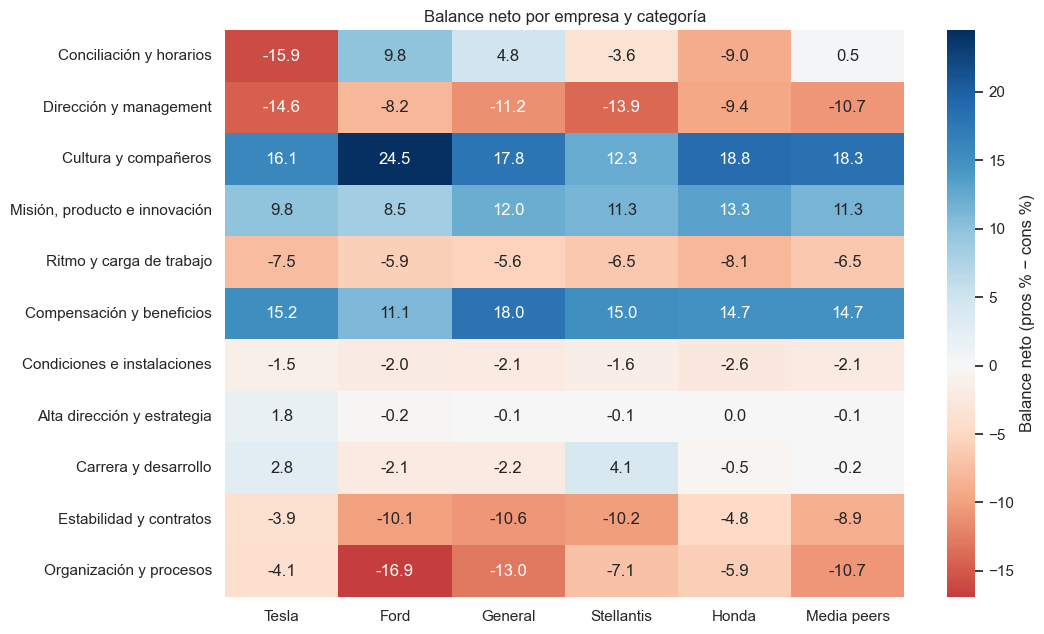

In [34]:
# Mapa de calor del balance neto
# Rojo: se critica más de lo que se elogia; azul: al revés.
fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(balance.loc[FIRMS + ['Media peers'], comparativa.index].T, annot=True, fmt='.1f',
            cmap='RdBu', center=0, ax=ax, cbar_kws={'label': 'Balance neto (pros % − cons %)'})
ax.set_xticklabels([nombre_corto(c.get_text()) for c in ax.get_xticklabels()], rotation=0)
ax.set_xlabel(''); ax.set_ylabel('')
plt.title('Balance neto por empresa y categoría'); plt.tight_layout(); plt.show()

### 4.2 Contraste con el rating y la recomendación

Si una categoría es un problema de verdad, las reseñas de Tesla que se quejan de ella deberían tener peor rating y menos recomendación que la media de Tesla.

,n reseñas,rating medio,% no recomienda
cat_cons,,,
Dirección y management,343,2.91,42.86
Alta dirección y estrategia,115,2.97,50.43
Estabilidad y contratos,78,3.13,39.74
Cultura y compañeros,115,3.17,35.65
Carrera y desarrollo,83,3.35,27.71
Compensación y beneficios,188,3.47,27.66
Organización y procesos,82,3.85,13.41
Conciliación y horarios,435,3.87,17.93
Ritmo y carga de trabajo,227,3.96,17.18


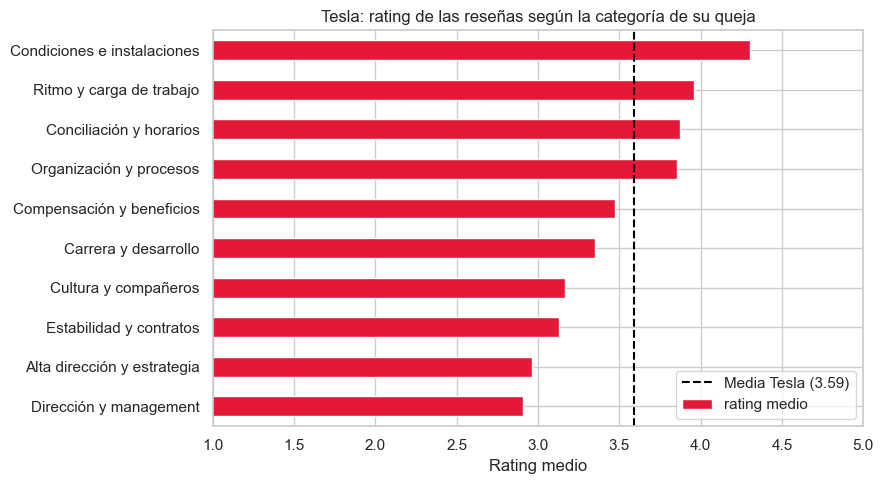

In [35]:
tesla = df[df['grupo'] == TARGET]

# Para cada categoría de cons: numero de reseñas de Tesla, su ratiing medio y su % de no recomendación
contraste = (tesla[tesla['cat_cons'].isin(CATS_NEGOCIO)]
             .groupby('cat_cons')
             .agg(**{'n reseñas': ('review_id', 'size'),
                     'rating medio': ('overall_rating', 'mean'),
                     '% no recomienda': ('recomienda', lambda s: pct(s == 'No'))}))
contraste = contraste[contraste['n reseñas'] >= 20]   # con menos de 20 reseñas la media no es fiable
contraste = contraste.sort_values('rating medio')
display(contraste.round(2))

# Gráfico: rating medio de quien se queja de cada categoría vs. rating medio global de Tesla
media_tesla = tesla['overall_rating'].mean()
ax = contraste['rating medio'].plot(kind='barh', figsize=(9, 5), color=COLORES[TARGET])
ax.axvline(media_tesla, color='black', ls='--', label=f'Media Tesla ({media_tesla:.2f})')
ax.set_xlim(1, 5); ax.set_xlabel('Rating medio'); ax.set_ylabel(''); ax.legend()
plt.title('Tesla: rating de las reseñas según la categoría de su queja'); plt.tight_layout(); plt.show()

### 4.3 Evolución en el tiempo

El EDA mostró que el rating de Tesla cae desde 2021. Para ver qué quejas acompañan esa caída sigo año a año el peso de las 4 categorías con más cons en Tesla.

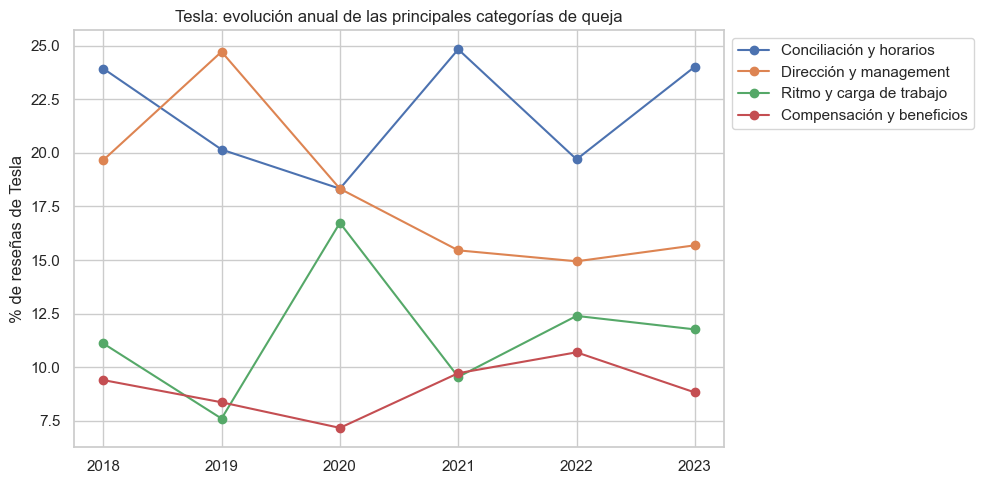

cat_cons,Conciliación y horarios,Dirección y management,Ritmo y carga de trabajo,Compensación y beneficios
anio,,,,
2018,23.9,19.7,11.1,9.4
2019,20.2,24.7,7.6,8.4
2020,18.3,18.3,16.7,7.2
2021,24.8,15.5,9.5,9.7
2022,19.7,14.9,12.4,10.7
2023,24.0,15.7,11.8,8.8


In [36]:
# Las 4 categorías con más peso en los cons de Tesla
top_cons = comparativa['Tesla cons %'].sort_values(ascending=False).head(4).index

# % de reseñas de Tesla de cada año cuyo con principal es cada categoría
evol_cat = (pd.crosstab(tesla['anio'], tesla['cat_cons'], normalize='index') * 100)[top_cons]

ax = evol_cat.plot(marker='o', figsize=(10, 5))
ax.set_ylabel('% de reseñas de Tesla'); ax.set_xlabel('')
plt.title('Tesla: evolución anual de las principales categorías de queja')
plt.legend(bbox_to_anchor=(1, 1)); plt.tight_layout(); plt.show()

evol_cat.round(1)

**Conclusión:**

- Tesla está peor que sus peers en lo que más pesa: Tiene el peor balance neto de las cinco empresas en Conciliación (−15,9 frente a +0,5 de los peers) y en Dirección y management (−14,6 frente a −10,7). Solo es mejor en categorías con poco peso en sus quejas: Organización, Estabilidad y Carrera.
- Las quejas sobre los mandos son las que más dañan la valoración: quien se queja de Dirección o Alta dirección puntúa a Tesla con 2,9, frente a 3,59 de media. Las quejas de horarios son muy frecuentes, pero castigan menos el rating.
- Son problemas crónicos: Conciliación se mantiene entre un 18 % y un 25 % de los cons todos los años.

---
## 5. Empleados actuales vs. antiguos

Los cons de quienes ya se han ido son, en la práctica, motivos de salida: el input más directo para un plan de retención.

Los antiguos empleados puntúan más bajo en todas las empresas. Por eso considero que la comparación útil es la de temas, no la de sentimiento o rating.

### 5.1 Tesla: quejas de actuales vs. antiguos

situacion,Actual,Antiguo,Diferencia (antiguo − actual)
cat_cons,,,
Dirección y management,14.3,20.7,6.4
Cultura y compañeros,5.2,6.4,1.2
Estabilidad y contratos,3.4,4.5,1.1
Alta dirección y estrategia,5.4,6.2,0.8
Carrera y desarrollo,4.0,4.4,0.4
"Misión, producto e innovación",0.0,0.0,0.0
Condiciones e instalaciones,1.7,1.2,-0.5
Otros,11.3,10.8,-0.5
Conciliación y horarios,22.2,21.1,-1.1


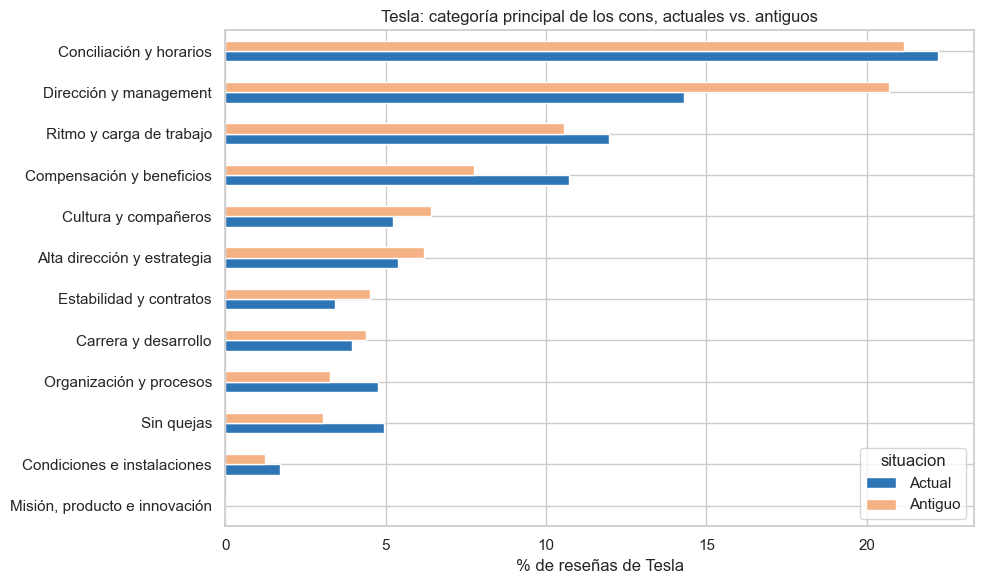

In [37]:
# % de reseñas de Tesla en cada categoría de cons, por separado actuales y antiguos
sit = pd.crosstab(tesla['cat_cons'], tesla['situacion'], normalize='columns').mul(100)
sit = sit.reindex(CATS_NEGOCIO + ['Sin quejas', 'Otros']).fillna(0)
sit['Diferencia (antiguo − actual)'] = sit['Antiguo'] - sit['Actual']   # > 0: pesa más entre quienes se fueron
sit = sit.sort_values('Diferencia (antiguo − actual)', ascending=False)
display(sit.round(1))

ax = sit.loc[CATS_NEGOCIO + ['Sin quejas'], ['Actual', 'Antiguo']].sort_values('Antiguo').plot(
    kind='barh', figsize=(10, 6), color=['#2E75B6', '#F4B183'])
ax.set_xlabel('% de reseñas de Tesla'); ax.set_ylabel('')
plt.title('Tesla: categoría principal de los cons, actuales vs. antiguos'); plt.tight_layout(); plt.show()

### 5.2 Motivos de salida: Tesla vs. peers

,Tesla %,Media peers %,Gap (pp)
cat_cons,,,
Conciliación y horarios,21.1,14.1,7.1
Dirección y management,20.7,15.2,5.5
Ritmo y carga de trabajo,10.6,7.7,2.8
Compensación y beneficios,7.8,8.9,-1.1
Cultura y compañeros,6.4,5.4,1.0
Alta dirección y estrategia,6.2,0.2,6.0
Estabilidad y contratos,4.5,10.0,-5.5
Carrera y desarrollo,4.4,8.0,-3.6
Organización y procesos,3.3,10.0,-6.7


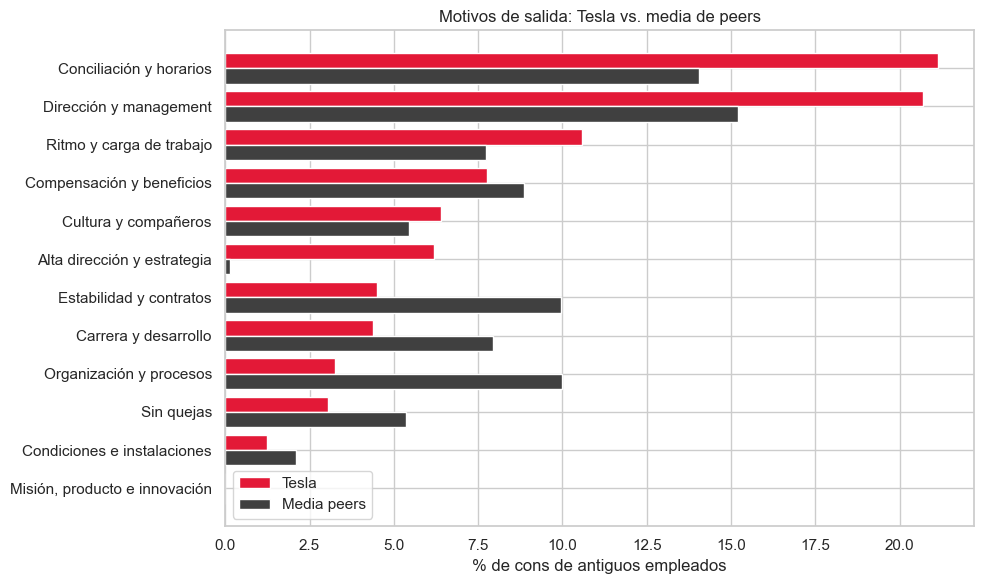

In [38]:
# Solo antiguos empleados: % de cada empresa en cada categoría de cons
antiguos = df[df['situacion'] == 'Antiguo']
salida = pd.crosstab(antiguos['firm'], antiguos['cat_cons'], normalize='index').mul(100)
salida = media_peers(salida.reindex(columns=CATS_NEGOCIO + ['Sin quejas'], fill_value=0))

motivos = pd.DataFrame({'Tesla %': salida.loc[TARGET], 'Media peers %': salida.loc['Media peers']})
motivos['Gap (pp)'] = motivos['Tesla %'] - motivos['Media peers %']   # > 0: motivo más frecuente en Tesla
motivos = motivos.sort_values('Tesla %', ascending=False)
display(motivos.round(1))

# Barras emparejadas Tesla vs. media de peers
fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(motivos))
ax.barh(y - 0.2, motivos['Tesla %'], height=0.4, color=COLORES[TARGET], label='Tesla')
ax.barh(y + 0.2, motivos['Media peers %'], height=0.4, color=COLORES['Peers'], label='Media peers')
ax.set_yticks(y); ax.set_yticklabels(motivos.index); ax.invert_yaxis()
ax.set_xlabel('% de cons de antiguos empleados'); ax.legend()
plt.title('Motivos de salida: Tesla vs. media de peers'); plt.tight_layout(); plt.show()

**Conclusión:**

- Los que se van tienen más problemas con sus managers: Dirección pesa un 20,7 % en los cons de los antiguos frente a un 14,3 % en los actuales, y un 15,2 % entre los antiguos de los peers.
- Conciliación y Ritmo pesan casi igual en actuales y antiguos (22 % frente a 21 % y 12 % frente a 11 %). Afectan a toda la plantilla, no solo a quien se va, y Conciliación es además el principal motivo de salida (21,1 % frente a 14,1 % en los peers). Es un problema serio y estructural que debe de ser tratado para el futuro.
- El salario no explica las salidas: los antiguos de Tesla se quejan menos de compensación que los de la competencia (7,8 % frente a 8,9 %).

---
## 6. Matriz de priorización

Un problema es prioritario si cumple dos condiciones a la vez: preocupa a muchos empleados y Tesla está peor que el mercado. La matriz cruza ambas para cada categoría:

| Eje | Cálculo | Qué mide |
|---|---|---|
| **X — Peso en los cons de Tesla** | Tesla cons % (tabla 4.1) | Tamaño del problema: cuántas reseñas de Tesla se quejan de esto |
| **Y — Desventaja frente a peers** | Tesla cons % − Peers cons % | Por encima de 0: Tesla recibe más quejas que el mercado en esa categoría |

La línea vertical es la mediana del peso, que separa categorías "grandes" y "pequeñas". La horizontal es el 0, que separa "peor que el mercado" y "igual o mejor". Salen cuatro cuadrantes:

| Cuadrante | Peso | Desventaja | Significado |
|---|---|---|---|
| **1. Primera Prioridad** | Alto | > 0 | Problema grande **y** propio de Tesla: actuar primero |
| **2. Segunda Prioridad** | Bajo | > 0 | Peor que el mercado, pero afecta a pocos: seguimiento |
| **3. Tercera Prioridad** | Alto | ≤ 0 | Problema grande pero común al sector: mantener, no diferencia a Tesla |
| **4. No prioritario** | Bajo | ≤ 0 | Ni grande ni diferencial |

El tamaño de cada punto es el **% no recomienda** de quien se queja de esa categoría (tabla 4.2): cuanto más grande, más daño hace esa queja a la recomendación de la empresa.

In [39]:
# Datos de la matriz: una fila por categoría de negocio
matriz = pd.DataFrame({
    'Peso en cons Tesla %': comparativa['Tesla cons %'],
    'Desventaja vs peers (pp)': comparativa['Tesla cons %'] - comparativa['Peers cons %'],
    'Gap neto': comparativa['Gap neto'],
})
# % no recomienda de quien se queja de cada categoría (tabla 4.2); vacío si había < 20 reseñas
matriz['% no recomienda'] = contraste['% no recomienda']

# Corte del eje X: la mediana del peso separa categorías "grandes" y "pequeñas"
corte_x = matriz['Peso en cons Tesla %'].median()
grande = matriz['Peso en cons Tesla %'] >= corte_x
peor = matriz['Desventaja vs peers (pp)'] > 0

# Cuadrante de cada categoría (las condiciones se evalúan en orden)
matriz['Cuadrante'] = np.select(
    [grande & peor, ~grande & peor, grande & ~peor],
    ['1. Primera Prioridad', '2. Segunda Prioridad', '3. Tercera Prioridad'],
    default='4. No Prioritario')

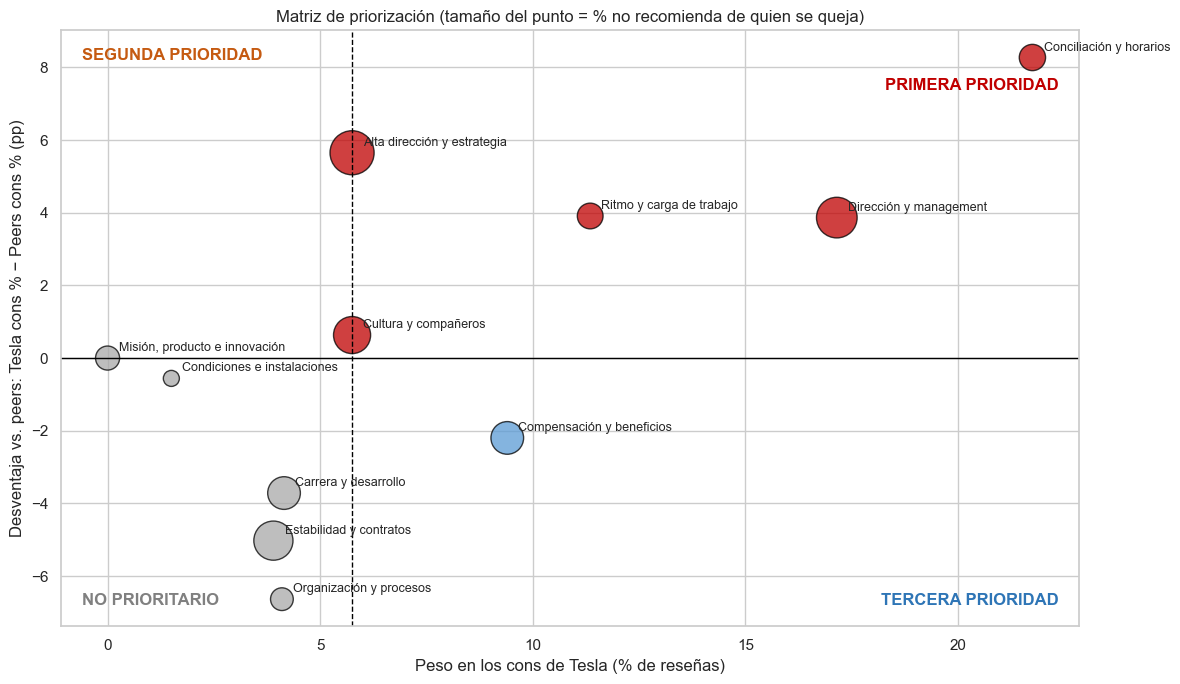

In [40]:
# Gráfico de dispersión: cada punto es una categoría
colores_cuad = {'1. Primera Prioridad': '#C00000', '2. Segunda Prioridad': '#F4B183',
                '3. Tercera Prioridad': '#5B9BD5', '4. No Prioritario': '#A9A9A9'}
# Tamaño del punto proporcional al % no recomienda (tamaño fijo si no hay dato)
tamanos = matriz['% no recomienda'].fillna(15) * 20

fig, ax = plt.subplots(figsize=(12, 7))
ax.scatter(matriz['Peso en cons Tesla %'], matriz['Desventaja vs peers (pp)'], s=tamanos,
           c=matriz['Cuadrante'].map(colores_cuad), alpha=0.75, edgecolor='black')
for cat, fila in matriz.iterrows():   # nombre de la categoría junto a su punto
    ax.annotate(cat, (fila['Peso en cons Tesla %'], fila['Desventaja vs peers (pp)']),
                xytext=(8, 5), textcoords='offset points', fontsize=9)

# Líneas que separan los cuadrantes
ax.axhline(0, color='black', lw=1)
ax.axvline(corte_x, color='black', lw=1, ls='--')

# Nombre de cada cuadrante en su esquina
ax.text(0.98, 0.92, 'PRIMERA PRIORIDAD', transform=ax.transAxes, ha='right', va='top', color='#C00000', fontweight='bold')
ax.text(0.02, 0.97, 'SEGUNDA PRIORIDAD', transform=ax.transAxes, ha='left', va='top', color='#C55A11', fontweight='bold')
ax.text(0.98, 0.03, 'TERCERA PRIORIDAD', transform=ax.transAxes, ha='right', va='bottom', color='#2E75B6', fontweight='bold')
ax.text(0.02, 0.03, 'NO PRIORITARIO', transform=ax.transAxes, ha='left', va='bottom', color='grey', fontweight='bold')

ax.set_xlabel('Peso en los cons de Tesla (% de reseñas)')
ax.set_ylabel('Desventaja vs. peers: Tesla cons % − Peers cons % (pp)')
ax.set_title('Matriz de priorización (tamaño del punto = % no recomienda de quien se queja)')
plt.tight_layout(); plt.show()

In [41]:
# Tabla de la matriz ordenada por cuadrante y, dentro de cada uno, por desventaja
matriz.sort_values(['Cuadrante', 'Desventaja vs peers (pp)'], ascending=[True, False]).round(1)

,Peso en cons Tesla %,Desventaja vs peers (pp),Gap neto,% no recomienda,Cuadrante
Conciliación y horarios,21.8,8.3,-16.4,17.9,1. Primera Prioridad
Alta dirección y estrategia,5.8,5.6,1.9,50.4,1. Primera Prioridad
Ritmo y carga de trabajo,11.4,3.9,-1.0,17.2,1. Primera Prioridad
Dirección y management,17.2,3.9,-3.9,42.9,1. Primera Prioridad
Cultura y compañeros,5.8,0.6,-2.3,35.7,1. Primera Prioridad
Compensación y beneficios,9.4,-2.2,0.5,27.7,3. Tercera Prioridad
"Misión, producto e innovación",0.0,0.0,-1.5,NaN,4. No Prioritario
Condiciones e instalaciones,1.5,-0.6,0.6,6.7,4. No Prioritario
Carrera y desarrollo,4.2,-3.7,2.9,27.7,4. No Prioritario
Estabilidad y contratos,3.9,-5.0,5.0,39.7,4. No Prioritario


**Cómo usar la matriz en las conclusiones:**
- Las categorías del cuadrante **Prioridad** son las candidatas a las recomendaciones de retención de la sección 7.
- Conviene confirmarlas con dos datos más: un **gap neto negativo** (tabla 4.1, también en la tabla anterior) y un **% no recomienda alto** (tamaño del punto).
- Si además aparecen como motivo de salida (tabla 5.2), la prioridad es máxima.
- **Higiene** no exige un plan específico frente a la competencia, pero empeorar en ella haría daño.

---
## 7. Conclusiones y recomendaciones para RRHH

Tesla puntúa por debajo del mercado (3,59 frente a 3,78) y empeora desde 2021. Sus problemas prioritarios son **conciliación** y **calidad de los mandos**: son las quejas más frecuentes, las que más la alejan de los peers y los principales motivos de salida (secciones 4 a 6).

### Recomendaciones
1. **Conciliación:** planificar turnos y horas extra con antelación y limitar las horas extra obligatorias. *Objetivo:* bajar el % de quejas de horarios (21,8 %) hacia el del mercado (13,5 %).
2. **Mandos intermedios:** formación en gestión de equipos, evaluación y entrevistas de salida. *Objetivo:* reducir las quejas de dirección entre quienes se van (20,7 %).
3. **Atracción:** destacar la estabilidad, la menor burocracia y el crecimiento, que son puntos donde Tesla supera al sector, siendo transparentes sobre el ritmo y los horarios.

### Limitaciones
- Las reseñas de Glassdoor son voluntarias y tienden a recoger experiencias extremas.
- No hay datos de país ni de puesto, así que se mezclan planta, ventas y oficinas.
- Cada reseña tiene asignado un único tema, y UMAP introduce algo de variabilidad entre ejecuciones.
- Por falta de tiempo no he podido afinar los modelos tanto de sentimiento con "transformers" entre otros puntos.

### Próximos pasos
- Clasificación multi-tema por reseña.
- Análisis por tipo de puesto con datos internos.
- Seguimiento periódico del balance neto por categoría.